# Attention Mechanisms: Multi-Head, Multi-Query, and Grouped-Query Attention

Modern LLMs rarely use the textbook multi-head attention unchanged. Most share keys and values across heads so that generation needs less memory. This notebook explains what is shared, why it helps, and what it costs. FlashAttention, which solves a different problem, has its own notebook: [FlashAttention](flash_attention.ipynb).

**What you will learn**

1. Why autoregressive decoding is limited by **reading the KV cache** from memory rather than by arithmetic.
2. How **MHA → GQA → MQA** differ in only one setting: the number of key/value heads.
3. How to implement all three variants with **one class**, and check that it is correct.
4. What sharing K/V heads costs, and how real models (Llama, Mistral, Falcon) make that trade-off.
5. *(Optional extension)* How **sliding-window attention** caps the cache length, how information still travels far through the layers, and why **attention sinks** are needed.

**Prerequisites:** scaled dot-product attention, tensor shapes, softmax, autoregressive decoding. Related notebooks: [Attention Is All You Need](Attention_Is_All_You_Need.ipynb) · [GPT-2](GPT-2.ipynb) · [positional encodings](positional_encodings.ipynb) · [key–value cache](key_value_cache.ipynb).

**Setup:** PyTorch and matplotlib only. Everything runs on a CPU in a few seconds. The memory calculations use sizes from **Llama-2-7B** (32 layers, 32 heads, head width 128, fp16).

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
B, T, d_model, n_heads = 2, 6, 32, 4
head_dim = d_model // n_heads
print(f"toy sizes: B={B}, T={T}, d_model={d_model}, n_heads={n_heads}, head_dim={head_dim}")

toy sizes: B=2, T=6, d_model=32, n_heads=4, head_dim=8


## 1. Reminder: attention as a soft lookup table

| Vector | Question it answers | Role |
| --- | --- | --- |
| Query `Q` | What am I looking for? | the current position's request |
| Key `K` | What do I offer as a match? | used **only for matching** |
| Value `V` | What do I actually pass on? | used **only for information transfer** |

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

**Multi-head attention (MHA)** runs `H` of these lookups in parallel, each on its own `head_dim = d_model / H` slice:

```text
Head 1: Q1 searches K1, retrieves V1
Head 2: Q2 searches K2, retrieves V2
...
Head H: QH searches KH, retrieves VH
```

- Each head has its **own** query, key, and value projections, so each can learn a different lookup, such as nearby tokens versus long-range dependencies.
- That flexibility has a cost at generation time. Section 2 shows what it is.

## 2. The decoding bottleneck: reading the KV cache

During autoregressive generation:

- each step processes **one** new token, so the query length is `Tq = 1`;
- that one query has to attend to **every** earlier token's key and value, in **every** layer;
- earlier keys and values never change, so they are stored in a **KV cache** instead of being recomputed.

For MHA, each layer caches:

```text
cached_K: (B, H, T_past, head_dim)
cached_V: (B, H, T_past, head_dim)
```

### Why reading the cache, not computing, is the limit

Consider one decoding step in one layer, for a single sequence (`B = 1`). Write `T` for the number of cached tokens (`T_past` above), `d` for `head_dim`, and `G` for the number of K/V heads (`G = H` for MHA). We count FLOPs (floating-point operations) with the usual convention that one multiply-add is 2 FLOPs.

**Step 1: scores, `q · Kᵀ`.** The new token's query in one head has shape `(1, d)`:

```text
q: (1, d)  @  Kᵀ: (d, T)   →   scores: (1, T)
```

Each of the `T` scores is a dot product of length `d`, costing `2d` FLOPs, so this product costs `2·T·d` FLOPs.

**Step 2: weighted sum, `weights · V`.** After the softmax:

```text
weights: (1, T)  @  V: (T, d)   →   output: (1, d)
```

Each of the `d` outputs is a sum of `T` products, so this product also costs `2·T·d` FLOPs.

One head therefore does `4·T·d` FLOPs, and the `H` query heads do `4·H·T·d`. The count is approximate: the softmax and the `1/√d` scaling add only about `T` operations per head, and the Q/K/V/O projections are a separate cost that is not counted here.

The cell below draws both products for toy sizes, so you can count the multiply-adds.

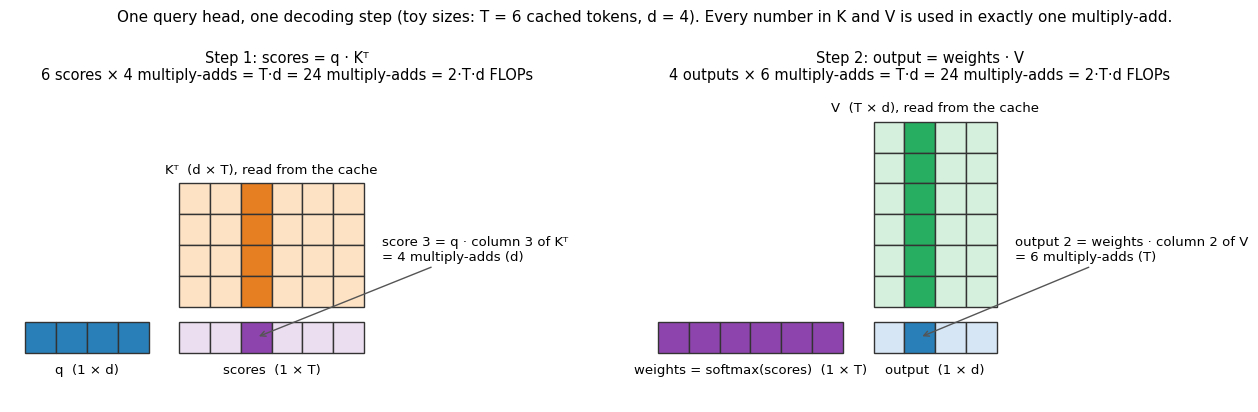

In [2]:
from matplotlib.patches import Rectangle

def draw_cells(ax, x0, y0, rows, cols, fc, hi_fc=None, hi=(), label=None, label_pos="above"):
    """Draw a rows x cols grid of unit cells with its lower-left corner at (x0, y0); cells in `hi` are highlighted."""
    for r in range(rows):
        for c in range(cols):
            color = hi_fc if (r, c) in hi else fc
            ax.add_patch(Rectangle((x0 + c, y0 + rows - 1 - r), 1, 1, fc=color, ec="#333", lw=1))
    if label:
        y = y0 + rows + 0.25 if label_pos == "above" else y0 - 0.35
        ax.text(x0 + cols / 2, y, label, ha="center", va="bottom" if label_pos == "above" else "top", fontsize=9.5)

def draw_one_head_flops(t=6, d=4, j=2, k=1):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
    blue, blue_hi = "#d6e6f5", "#2980b9"
    orange, orange_hi = "#fde2c4", "#e67e22"
    green, green_hi = "#d5f0dc", "#27ae60"
    purple, purple_hi = "#ebdef0", "#8e44ad"

    # Step 1: q (1 x d) times K^T (d x T) gives scores (1 x T); score j uses column j of K^T.
    draw_cells(ax1, 0, 0, 1, d, blue, blue_hi, {(0, c) for c in range(d)}, "q  (1 × d)", "below")
    draw_cells(ax1, d + 1, 1.5, d, t, orange, orange_hi, {(r, j) for r in range(d)}, "Kᵀ  (d × T), read from the cache")
    draw_cells(ax1, d + 1, 0, 1, t, purple, purple_hi, {(0, j)}, "scores  (1 × T)", "below")
    ax1.annotate(f"score {j + 1} = q · column {j + 1} of Kᵀ\n= {d} multiply-adds (d)", xy=(d + 1.5 + j, 0.5),
                 xytext=(d + t + 1.6, 3.0), fontsize=9.5, arrowprops=dict(arrowstyle="->", color="#555"))
    ax1.set_title(f"Step 1: scores = q · Kᵀ\n{t} scores × {d} multiply-adds = T·d = {t * d} multiply-adds = 2·T·d FLOPs", fontsize=10.5)

    # Step 2: weights (1 x T) times V (T x d) gives output (1 x d); output k uses column k of V.
    draw_cells(ax2, 0, 0, 1, t, purple, purple_hi, {(0, c) for c in range(t)}, "weights = softmax(scores)  (1 × T)", "below")
    draw_cells(ax2, t + 1, 1.5, t, d, green, green_hi, {(r, k) for r in range(t)}, "V  (T × d), read from the cache")
    draw_cells(ax2, t + 1, 0, 1, d, blue, blue_hi, {(0, k)}, "output  (1 × d)", "below")
    ax2.annotate(f"output {k + 1} = weights · column {k + 1} of V\n= {t} multiply-adds (T)", xy=(t + 1.5 + k, 0.5),
                 xytext=(t + d + 1.6, 3.0), fontsize=9.5, arrowprops=dict(arrowstyle="->", color="#555"))
    ax2.set_title(f"Step 2: output = weights · V\n{d} outputs × {t} multiply-adds = T·d = {t * d} multiply-adds = 2·T·d FLOPs", fontsize=10.5)

    for ax in (ax1, ax2):
        ax.set_xlim(-0.5, 17.5); ax.set_ylim(-1.6, 8.6); ax.set_aspect("equal"); ax.axis("off")
    fig.suptitle(f"One query head, one decoding step (toy sizes: T = {t} cached tokens, d = {d}). "
                 "Every number in K and V is used in exactly one multiply-add.", fontsize=11)
    plt.tight_layout(); plt.show()

draw_one_head_flops()


**Reading the figure**

- Each highlighted column produces one number: a score needs `d` multiply-adds, and an output value needs `T`.
- Every cell of `K` and of `V` takes part in **exactly one** multiply-add. So for one query head, the FLOP count is simply 2 FLOPs for each cached number: `2 · (T·d + T·d) = 4·T·d`.

**Memory read.** The arithmetic grows with `H` because **every query head** does its own two products. The memory read grows with `G`, because the query heads that share a K/V head use **the same** cached tensors, which are read once for the whole group:

```text
2 tensors (K and V) × G heads × T tokens × d values × 2 bytes (fp16)  =  4·G·T·d bytes
```

| | Amount |
| --- | --- |
| Arithmetic: `q·K` and `weights·V` for `H` heads | `≈ 4 · H · T · head_dim` FLOPs |
| Cache read: `K` and `V` for `G` heads, 2 bytes each | `= 4 · G · T · head_dim` bytes |
| **Arithmetic per byte read** | **`H / G` FLOP/byte** |

The factor `4·T·d` cancels in the ratio: 2 products × 2 FLOPs on top, 2 tensors × 2 bytes underneath. This ratio is called the **arithmetic intensity**.

The cell below shows the same ratio as blocks for 8 query heads, using the three variants that section 3 explains in detail. Each blue block is one query head's arithmetic (`4·T·d` FLOPs), and each orange block is one K/V head read from the cache (`4·T·d` bytes).

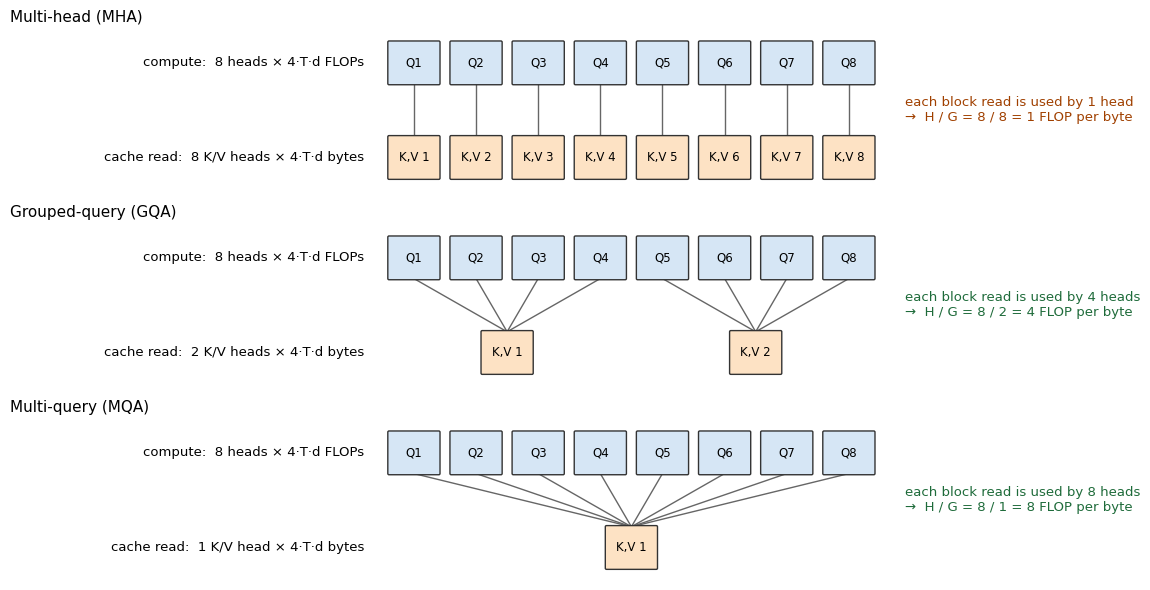

In [3]:
from matplotlib.patches import FancyBboxPatch

def draw_flops_vs_bytes(n_q=8, variants=(("Multi-head (MHA)", 8), ("Grouped-query (GQA)", 2), ("Multi-query (MQA)", 1))):
    fig, axes = plt.subplots(len(variants), 1, figsize=(12, 2.0 * len(variants)))
    for ax, (title, n_kv) in zip(axes, variants):
        group = n_q // n_kv
        for g in range(n_kv):
            center = g * group + (group - 1) / 2
            for h in range(g * group, (g + 1) * group):
                ax.add_patch(FancyBboxPatch((h - 0.4, 1.6), 0.8, 0.7, boxstyle="round,pad=0.02", fc="#d6e6f5", ec="#333", zorder=2))
                ax.text(h, 1.95, f"Q{h + 1}", ha="center", va="center", fontsize=8.5, zorder=3)
                ax.plot([h, center], [1.6, 0.7], color="#666", lw=1, zorder=1)
            ax.add_patch(FancyBboxPatch((center - 0.4, 0), 0.8, 0.7, boxstyle="round,pad=0.02", fc="#fde2c4", ec="#333", zorder=2))
            ax.text(center, 0.35, f"K,V {g + 1}", ha="center", va="center", fontsize=8.5, zorder=3)
        ax.text(-0.8, 1.95, f"compute:  {n_q} heads × 4·T·d FLOPs", ha="right", va="center", fontsize=9.5)
        ax.text(-0.8, 0.35, f"cache read:  {n_kv} K/V head{'s' if n_kv > 1 else ''} × 4·T·d bytes", ha="right", va="center", fontsize=9.5)
        ax.text(n_q - 0.1, 1.15, f"each block read is used by {group} head{'s' if group > 1 else ''}\n"
                                 f"→  H / G = {n_q} / {n_kv} = {group} FLOP per byte",
                ha="left", va="center", fontsize=9.5, color="#a04000" if group == 1 else "#1e6b3a")
        ax.set_title(title, fontsize=11, loc="left")
        ax.set_xlim(-6.5, n_q + 3.6); ax.set_ylim(-0.2, 2.5); ax.axis("off")
    plt.tight_layout(); plt.show()

draw_flops_vs_bytes()


**Reading the figure**

- The compute row is **the same** in all three variants: 8 query heads, each doing its own `4·T·d` FLOPs.
- Only the cache-read row shrinks. Each orange block is read **once** and then used by every query head connected to it.
- The FLOP/byte ratio is just the number of blue blocks per orange block, `H/G`.

**Worked example: Llama-2-7B** (`H = 32`, `d = 128`) with `T = 4096` cached tokens, one layer:

| | MHA (`G = 32`) | GQA-8 (`G = 8`) |
| --- | ---: | ---: |
| FLOPs | 4 · 32 · 4096 · 128 ≈ 67 million | ≈ 67 million (unchanged) |
| Bytes read | 4 · 32 · 4096 · 128 ≈ 67 MB | 4 · 8 · 4096 · 128 ≈ 17 MB |
| FLOP per byte | 1 | 4 |

Over all 32 layers, MHA reads about 2.1 GB of cache to generate **one** token.

To see what these numbers mean in time, the cell below divides them by the peak speeds of an NVIDIA A100 80 GB GPU: about 312 TFLOP/s for fp16 arithmetic on its tensor cores and about 2.0 TB/s for reading memory (NVIDIA's published peak figures). Real kernels reach less than peak, so treat the times as idealised lower bounds.

MHA     67.1 M FLOPs   67.1 MB read  compute  0.22 µs  read 33.55 µs
GQA-8   67.1 M FLOPs   16.8 MB read  compute  0.22 µs  read  8.39 µs
MQA     67.1 M FLOPs    2.1 MB read  compute  0.22 µs  read  1.05 µs


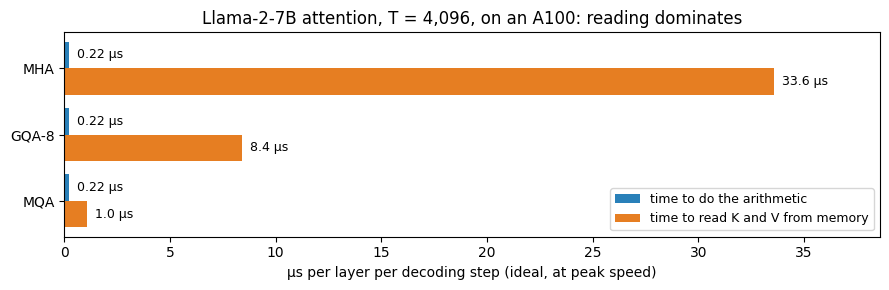

In [4]:
q_heads, d_head, t_cache = 32, 128, 4096          # Llama-2-7B attention, 4,096 cached tokens
PEAK_FLOPS, PEAK_BYTES_PER_S = 312e12, 2.0e12     # A100 80 GB peak: fp16 tensor-core FLOP/s, memory bytes/s

names, compute_us, read_us = [], [], []
for name, kv_heads in [("MHA", 32), ("GQA-8", 8), ("MQA", 1)]:
    flops = 4 * q_heads * t_cache * d_head
    bytes_read = 4 * kv_heads * t_cache * d_head
    names.append(name)
    compute_us.append(flops / PEAK_FLOPS * 1e6)
    read_us.append(bytes_read / PEAK_BYTES_PER_S * 1e6)
    print(f"{name:<6} {flops / 1e6:5.1f} M FLOPs  {bytes_read / 1e6:5.1f} MB read  "
          f"compute {compute_us[-1]:5.2f} µs  read {read_us[-1]:5.2f} µs")

fig, ax = plt.subplots(figsize=(9, 3))
y = range(len(names))
ax.barh([i - 0.2 for i in y], compute_us, height=0.4, color="#2980b9", label="time to do the arithmetic")
ax.barh([i + 0.2 for i in y], read_us, height=0.4, color="#e67e22", label="time to read K and V from memory")
for i in y:
    ax.text(read_us[i] + 0.4, i + 0.2, f"{read_us[i]:.1f} µs", va="center", fontsize=9)
    ax.text(compute_us[i] + 0.4, i - 0.2, f"{compute_us[i]:.2f} µs", va="center", fontsize=9)
ax.set_yticks(list(y)); ax.set_yticklabels(names); ax.invert_yaxis()
ax.set_xlabel("µs per layer per decoding step (ideal, at peak speed)")
ax.set_title("Llama-2-7B attention, T = 4,096, on an A100: reading dominates")
ax.legend(fontsize=9, loc="lower right"); ax.set_xlim(0, max(read_us) * 1.15)
plt.tight_layout(); plt.show()


**Reading the chart**

- The arithmetic takes about 0.2 µs in every variant, while reading the MHA cache takes about 34 µs, roughly 150 times longer. The arithmetic and the reading overlap, so a step takes about as long as the slower of the two: the read.
- GQA-8 and MQA cut the read time by 4× and 32× and leave the arithmetic unchanged.

**Interpretation**

- With MHA (`G = H`), attention does about **1 FLOP per byte** read. A modern GPU can do on the order of 100 FLOPs in the time it takes to read one byte from memory, so it finishes the arithmetic quickly and spends most of the step **waiting for data**.
- The arithmetic is fixed by the number of query heads, since each head still has to compute its own scores and output. **The only way to speed this up is to read fewer bytes**, which means storing fewer K/V heads.
- Batching does not help here. Each sequence has its own cache, so a batch of `B` sequences multiplies both the FLOPs and the bytes by `B`, and the ratio stays `H/G`. The weight matrix multiplications behave differently: one read of the weights is reused for every sequence in the batch. This is why the KV cache, not the weights, becomes the bottleneck at large batch sizes and long contexts.

> Do all heads really need **separate** keys and values? Or is it enough for each head to ask its own question (a separate query) and search a **shared** table?

## 3. Sharing K/V heads: MHA → GQA → MQA

All three variants keep `H` query heads. They differ in only one setting: the number of K/V heads, `G`.

| Variant | Query heads | K/V heads `G` | Who shares what | KV cache vs. MHA |
| --- | ---: | ---: | --- | ---: |
| Multi-head attention (MHA) | `H` | `H` | nothing is shared | 1× |
| Grouped-query attention (GQA) | `H` | `1 < G < H` | each group of `H/G` query heads shares one K/V head | `G/H` |
| Multi-query attention (MQA) | `H` | `1` | all query heads share one K/V head | `1/H` |

In the figure, colors show which query heads share a K/V head.

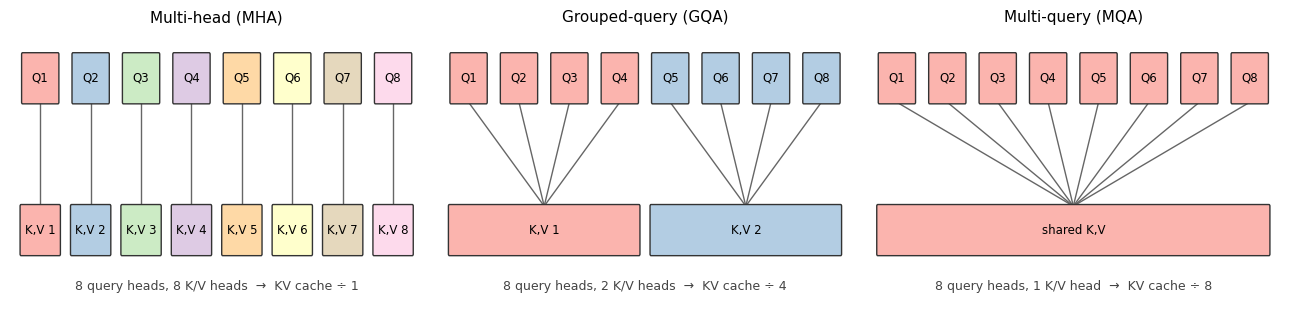

In [2]:
from matplotlib.patches import FancyBboxPatch

def draw_head_sharing(n_q=8, variants=(("Multi-head (MHA)", 8), ("Grouped-query (GQA)", 2), ("Multi-query (MQA)", 1))):
    palette = plt.cm.Pastel1.colors
    fig, axes = plt.subplots(1, len(variants), figsize=(13, 3.3))
    for ax, (title, n_kv) in zip(axes, variants):
        group = n_q // n_kv
        ax.set_xlim(-0.6, n_q - 0.4); ax.set_ylim(-1.0, 2.5); ax.axis("off")
        for g in range(n_kv):
            color = palette[g % len(palette)]
            left, right = g * group, (g + 1) * group - 1
            center = (left + right) / 2
            ax.add_patch(FancyBboxPatch((left - 0.38, -0.3), right - left + 0.76, 0.6,
                                        boxstyle="round,pad=0.02", fc=color, ec="#333", zorder=2))
            ax.text(center, 0, f"K,V {g + 1}" if group < n_q else "shared K,V", ha="center", va="center", fontsize=8.5, zorder=3)
            for q in range(left, right + 1):
                ax.add_patch(FancyBboxPatch((q - 0.35, 1.6), 0.7, 0.6, boxstyle="round,pad=0.02",
                                            fc=color, ec="#333", zorder=2))
                ax.text(q, 1.9, f"Q{q + 1}", ha="center", va="center", fontsize=8.5, zorder=3)
                ax.plot([q, center], [1.6, 0.3], color="#666", lw=1, zorder=1)
        ax.set_title(title, fontsize=11)
        ax.text((n_q - 1) / 2, -0.75, f"{n_q} query heads, {n_kv} K/V head{'s' if n_kv > 1 else ''}  →  KV cache ÷ {group}",
                ha="center", fontsize=9, color="#444")
    plt.tight_layout(); plt.show()

draw_head_sharing()

**Reading the figure**

- **Every variant still has 8 query heads**, so it still produces 8 different attention patterns. MQA does **not** remove heads.
- Only the bottom row, the part that is cached and read at every step, gets smaller.
- For each query head, the formula is unchanged; only the K and V it reads differ:

$$\operatorname{head}_h=\operatorname{softmax}\!\left(\frac{Q_h K_{g(h)}^\top}{\sqrt{d_k}}\right)V_{g(h)},\qquad g(h)=\lfloor h\,/\,(H/G)\rfloor$$

## 4. One class for all three variants

Compared with standard MHA, there are only two changes:

1. `W_k` and `W_v` produce `G · head_dim` features instead of `H · head_dim`.
2. Before attention, each K/V head is **repeated** for the `H/G` query heads in its group (`repeat_interleave`).

The cache stores K and V **before** they are repeated, which is where the memory saving comes from. The class also supports a causal mask and an optional cache, both used in Section 5.

In [3]:
class GroupedQueryAttention(nn.Module):
    """n_kv_heads = n_heads -> MHA;  1 < n_kv_heads < n_heads -> GQA;  n_kv_heads = 1 -> MQA."""

    def __init__(self, d_model, n_heads, n_kv_heads):
        super().__init__()
        assert d_model % n_heads == 0 and n_heads % n_kv_heads == 0
        self.n_heads, self.n_kv_heads = n_heads, n_kv_heads
        self.head_dim = d_model // n_heads
        self.group_size = n_heads // n_kv_heads                                # query heads per K/V head
        self.W_q = nn.Linear(d_model, n_heads * self.head_dim, bias=False)
        self.W_k = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)  # change 1: fewer K/V heads
        self.W_v = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.W_o = nn.Linear(n_heads * self.head_dim, d_model, bias=False)

    def split_heads(self, x, n):                                   # (B, T, n*Dh) -> (B, n, T, Dh)
        B, T, _ = x.shape
        return x.view(B, T, n, self.head_dim).transpose(1, 2)

    def forward(self, x, cache=None, causal=True):
        """x: (B, T_new, D). cache: (K, V) from earlier steps, each (B, n_kv_heads, T_past, Dh)."""
        B, T_new, _ = x.shape
        Q = self.split_heads(self.W_q(x), self.n_heads)            # (B, H, T_new, Dh)
        K = self.split_heads(self.W_k(x), self.n_kv_heads)         # (B, G, T_new, Dh)
        V = self.split_heads(self.W_v(x), self.n_kv_heads)
        if cache is not None:                                      # append to earlier tokens' keys/values
            K, V = torch.cat([cache[0], K], dim=2), torch.cat([cache[1], V], dim=2)
        new_cache = (K, V)                                         # stored with only G heads

        # change 2: share each K/V head across its group, (B, G, Tk, Dh) -> (B, H, Tk, Dh)
        K_shared = K.repeat_interleave(self.group_size, dim=1)
        V_shared = V.repeat_interleave(self.group_size, dim=1)

        scores = Q @ K_shared.transpose(-2, -1) / math.sqrt(self.head_dim)    # (B, H, T_new, Tk)
        if causal and T_new > 1:
            T_k = K.size(2)                                        # new queries sit at the end of the sequence
            future = torch.triu(torch.ones(T_new, T_k, dtype=torch.bool), diagonal=T_k - T_new + 1)
            scores = scores.masked_fill(future, float("-inf"))
        weights = scores.softmax(dim=-1)
        out = (weights @ V_shared).transpose(1, 2).reshape(B, T_new, -1)       # merge heads
        return self.W_o(out), weights, new_cache


x = torch.randn(B, T, d_model)
print(f"{'variant':<6}{'K/V heads':>10}   {'cached K':<16}{'scores':<18}{'output'}")
for name, G in [("MHA", 4), ("GQA", 2), ("MQA", 1)]:
    out, weights, (K, V) = GroupedQueryAttention(d_model, n_heads, n_kv_heads=G)(x)
    print(f"{name:<6}{G:>10}   {str(tuple(K.shape)):<16}{str(tuple(weights.shape)):<18}{tuple(out.shape)}")

variant K/V heads   cached K        scores            output
MHA            4   (2, 4, 6, 8)    (2, 4, 6, 6)      (2, 6, 32)
GQA            2   (2, 2, 6, 8)    (2, 4, 6, 6)      (2, 6, 32)
MQA            1   (2, 1, 6, 8)    (2, 4, 6, 6)      (2, 6, 32)


### Under the hood: how one K/V head serves a group of query heads

Inside `forward`, the projections give different numbers of heads:

```text
Q : (B, H, T_new, Dh)    H query heads
K : (B, G, Tk,    Dh)    only G key heads     (G < H for GQA and MQA)
V : (B, G, Tk,    Dh)
```

The next step, `Q @ K.transpose(-2, -1)`, multiplies head by head along dim 1. That only works if both tensors have `H` heads there, or if one of them has exactly 1 head, which PyTorch can broadcast. For GQA with `H = 4` and `G = 2`, neither is true. So "change 2" expands `K` and `V` to `H` heads first.

**What `repeat_interleave` does.** `group_size = H // G` is the number of query heads that share one K/V head. `repeat_interleave(group_size, dim=1)` copies each head along the head axis, putting the copies **next to each other**:

```text
H = 4, G = 2, group_size = 2

K heads         : [k0, k1]            (B, 2, Tk, Dh)    e.g. (2, 2, 6, 8) above
K_shared heads  : [k0, k0, k1, k1]    (B, 4, Tk, Dh)    e.g. (2, 4, 6, 8)
query heads     : [q0, q1, q2, q3]
                   └─┬──┘  └─┬──┘
                  use k0   use k1
```

Query heads 0 and 1 use K/V head 0, and heads 2 and 3 use K/V head 1. That is the mapping `g(h) = ⌊h / (H/G)⌋` in the formula from Section 3, and it is what "grouped" means: consecutive query heads form a group that shares one K and one V. `V` is expanded the same way, so each head's attention weights are applied to the values that belong to its own keys.

**Why `repeat_interleave` and not `repeat`.** `K.repeat(1, group_size, 1, 1)` tiles the heads instead, giving `[k0, k1, k0, k1]`. Query heads 0 and 2 would then share `k0`. A model trained that way would also work, but it is a different grouping, and the grouping must match the weights. Section 6 builds a GQA model from MHA weights by averaging the K/V heads of consecutive query heads (`[0, 1]` and `[2, 3]`), which matches `repeat_interleave`. Hugging Face's Llama implementation (`repeat_kv`) uses the same consecutive grouping.

**The three variants are special cases of the same two lines.**

| Variant | `G` | `group_size` | What the two lines do |
| --- | --- | --- | --- |
| MHA | `H` | 1 | nothing: each head is "repeated" once |
| GQA | between 1 and `H` | `H/G` | copy each K/V head for its group |
| MQA | 1 | `H` | copy the single K/V head to all `H` query heads |

For MQA the copy is not strictly needed, because a size-1 head axis broadcasts. The second correctness check below confirms that both give the same output.

**Why the cache is saved before the repeat.** `new_cache = (K, V)` comes before `repeat_interleave`, so the cache holds only `G` heads. The copies add no information, because each is identical to its source head. Storing `G` heads instead of `H` is exactly the `H/G` memory saving, and the expansion is simply redone at every step.

GPU kernels go further and read each K/V head from memory once, then reuse it for every query head in its group. That is where the decoding speed-up from Section 2 actually comes from. In PyTorch, `F.scaled_dot_product_attention(..., enable_gqa=True)` does this for you (see Section 6 of the [FlashAttention](flash_attention.ipynb) notebook).

**Reading the shapes**

- **Cached K** shrinks from 4 heads to 2 to 1. This is the saving.
- **Scores** stay `(B, H, T, T)` in all three variants: every query head still computes its own attention distribution.
- **Output** is unchanged, so the variants can be swapped for one another inside a Transformer block.

### Correctness checks

1. With `G = H`, the class should exactly match PyTorch's `nn.MultiheadAttention`.
2. With `G = 1`, repeating the single K/V head should equal **broadcasting** it, since PyTorch can reuse a size-1 head axis without copying.

In [4]:
mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)

# 1. G = H is ordinary multi-head attention.
mha = GroupedQueryAttention(d_model, n_heads, n_kv_heads=n_heads)
ref = nn.MultiheadAttention(d_model, n_heads, bias=False, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mha.W_q.weight, mha.W_k.weight, mha.W_v.weight]))
    ref.out_proj.weight.copy_(mha.W_o.weight)
    ours, _, _ = mha(x)
    theirs, _ = ref(x, x, x, attn_mask=mask, need_weights=False)
print("G = H matches nn.MultiheadAttention:", torch.allclose(ours, theirs, atol=1e-5))

# 2. G = 1: repeat_interleave gives the same result as broadcasting a size-1 head axis.
mqa = GroupedQueryAttention(d_model, n_heads, n_kv_heads=1)
with torch.no_grad():
    out_repeat, _, _ = mqa(x)
    Q = mqa.split_heads(mqa.W_q(x), n_heads)       # (B, H, T, Dh)
    K = mqa.split_heads(mqa.W_k(x), 1)             # (B, 1, T, Dh) -- broadcast across the H query heads
    V = mqa.split_heads(mqa.W_v(x), 1)
    s = (Q @ K.transpose(-2, -1) / math.sqrt(head_dim)).masked_fill(mask, float("-inf"))
    out_broadcast = mqa.W_o((s.softmax(-1) @ V).transpose(1, 2).reshape(B, T, d_model))
print("G = 1: repeat == broadcast:", torch.allclose(out_repeat, out_broadcast, atol=1e-6))

assert torch.allclose(ours, theirs, atol=1e-5) and torch.allclose(out_repeat, out_broadcast, atol=1e-6)

G = H matches nn.MultiheadAttention: True
G = 1: repeat == broadcast: True


### Shared keys, different attention patterns

Below are the four query heads of a randomly initialized **MQA** layer, which has a single K/V head. The inputs are scaled up so that the random-weight patterns are sharp enough to see.

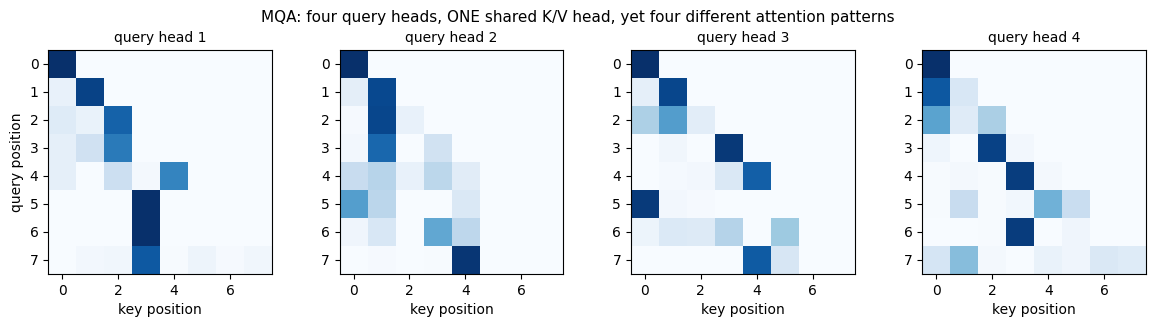

largest weight difference between any two heads: 1.00


In [5]:
torch.manual_seed(0)
mqa = GroupedQueryAttention(d_model, n_heads, n_kv_heads=1)
x_demo = 3 * torch.randn(1, 8, d_model)
with torch.no_grad():
    _, w, _ = mqa(x_demo)

fig, axes = plt.subplots(1, n_heads, figsize=(12, 3.1))
for h, ax in enumerate(axes):
    ax.imshow(w[0, h], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"query head {h + 1}", fontsize=10)
    ax.set_xlabel("key position")
axes[0].set_ylabel("query position")
fig.suptitle("MQA: four query heads, ONE shared K/V head, yet four different attention patterns", fontsize=11)
plt.tight_layout(); plt.show()

diffs = [(w[0, i] - w[0, j]).abs().max().item() for i in range(n_heads) for j in range(i + 1, n_heads)]
print(f"largest weight difference between any two heads: {max(diffs):.2f}")

- Every head reads the **same** keys, but each head's **query** is different, so its dot products and therefore its softmax weights differ.
- The patterns are lower-triangular because of the causal mask.

## 5. Decoding with a KV cache

Generation happens in two phases:

1. **Prefill:** run the whole prompt at once and store its K and V.
2. **Decode:** for each new token, compute only **its** Q, K, and V, append K and V to the cache, and attend over the whole cache.

The cell below runs both phases with a single attention layer, using random vectors in place of token embeddings. It prints the cached `K` shape after each step and checks that the cached result equals a full recomputation.

In [6]:
torch.manual_seed(1)
prompt = torch.randn(1, 5, d_model)       # stand-ins for 5 prompt-token embeddings
new_tokens = torch.randn(1, 3, d_model)   # stand-ins for 3 generated tokens

for name, G in [("MHA", 4), ("GQA", 2), ("MQA", 1)]:
    layer = GroupedQueryAttention(d_model, n_heads, n_kv_heads=G)
    with torch.no_grad():
        _, _, cache = layer(prompt)                                   # prefill
        shapes, step_outputs = [tuple(cache[0].shape)], []
        for t in range(new_tokens.size(1)):                           # decode one token at a time
            out, _, cache = layer(new_tokens[:, t:t + 1], cache=cache)
            step_outputs.append(out)
            shapes.append(tuple(cache[0].shape))
        full, _, _ = layer(torch.cat([prompt, new_tokens], dim=1))    # no cache: recompute everything
    same = torch.allclose(torch.cat(step_outputs, dim=1), full[:, -3:], atol=1e-5)
    print(f"{name}  cached K: {' → '.join(str(s) for s in shapes)}   matches full recompute: {same}")
    assert same

MHA  cached K: (1, 4, 5, 8) → (1, 4, 6, 8) → (1, 4, 7, 8) → (1, 4, 8, 8)   matches full recompute: True
GQA  cached K: (1, 2, 5, 8) → (1, 2, 6, 8) → (1, 2, 7, 8) → (1, 2, 8, 8)   matches full recompute: True
MQA  cached K: (1, 1, 5, 8) → (1, 1, 6, 8) → (1, 1, 7, 8) → (1, 1, 8, 8)   matches full recompute: True


- The **sequence axis** (third dimension) grows by one per generated token.
- The **head axis** (second dimension) is 4, 2, or 1. That is the factor by which GQA and MQA shrink what has to be stored and read at every step.
- The cache changes only the amount of work, not the result: the cached outputs equal a full recomputation.

## 6. At real scale: memory, parameters, and the trade-off

The cell below uses Llama-2-7B's sizes and draws two charts:

- **Left:** KV cache for one 4,096-token sequence, by number of K/V heads.
- **Right:** memory that must be **read at every decoding step** (the weights plus every sequence's cache) as the batch grows. The model weights are read once per step no matter the batch size; the cache grows with batch × context length.

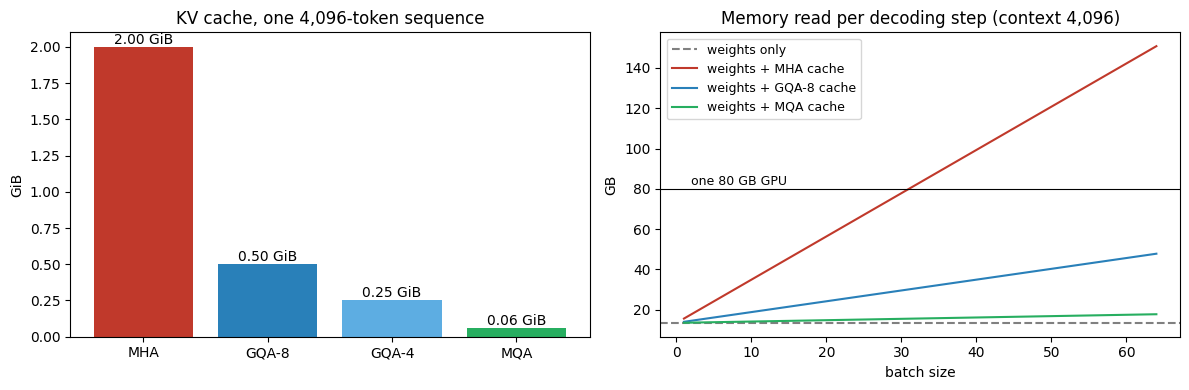

variant    K+V projection params / layer    arith. intensity (FLOP/byte)
MHA                              33.6 M                               1
GQA-8                             8.4 M                               4
GQA-4                             4.2 M                               8
MQA                               1.0 M                              32


In [7]:
N_LAYERS, H, DH, BYTES = 32, 32, 128, 2          # Llama-2-7B-like, fp16
WEIGHTS_GB = 6.7e9 * BYTES / 1e9                  # ~6.7B parameters

def kv_cache_bytes(batch, seq_len, kv_heads, n_layers=N_LAYERS, head_dim=DH, bytes_per_value=BYTES):
    return 2 * batch * kv_heads * seq_len * head_dim * n_layers * bytes_per_value   # 2 = K and V

variants = [("MHA", 32), ("GQA-8", 8), ("GQA-4", 4), ("MQA", 1)]
colors = ["#c0392b", "#2980b9", "#5dade2", "#27ae60"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sizes = [kv_cache_bytes(1, 4096, G) / 2**30 for _, G in variants]
bars = ax1.bar([n for n, _ in variants], sizes, color=colors)
ax1.bar_label(bars, fmt="%.2f GiB")
ax1.set_title("KV cache, one 4,096-token sequence"); ax1.set_ylabel("GiB")

batches = torch.arange(1, 65)
ax2.axhline(WEIGHTS_GB, color="gray", ls="--", label="weights only")
for (name, G), c in zip([variants[0], variants[1], variants[3]], [colors[0], colors[1], colors[3]]):
    ax2.plot(batches, [WEIGHTS_GB + kv_cache_bytes(int(b), 4096, G) / 1e9 for b in batches], color=c, label=f"weights + {name} cache")
ax2.axhline(80, color="black", lw=0.8); ax2.text(2, 82, "one 80 GB GPU", fontsize=9)
ax2.set_title("Memory read per decoding step (context 4,096)")
ax2.set_xlabel("batch size"); ax2.set_ylabel("GB"); ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"{'variant':<8}{'K+V projection params / layer':>32}{'arith. intensity (FLOP/byte)':>32}")
for name, G in variants:
    print(f"{name:<8}{2 * H * DH * G * DH / 1e6:>29.1f} M{H / G:>32.0f}")

**Reading the charts**

- **Cache size:** GQA-8 needs a quarter of the MHA cache, and MQA needs 1/32 of it.
- **Batching:** with MHA the cache outgrows the weights at about 7 sequences, and weights plus cache exceed one 80 GB GPU at about 32. With GQA-8, batch 64 still fits in under 50 GB. GQA and MQA let the same GPU serve much larger batches or longer contexts.
- **Parameters:** the `K` and `V` projections shrink by the same factor `H/G`. The query and output projections are unchanged.
- **Arithmetic intensity** rises from 1 to `H/G` FLOP per byte, so less of each step is spent waiting on memory.

### Where GQA and MQA help, and where they do not

GQA and MQA change one thing: the KV cache becomes `H/G` times smaller. During **decoding**, that smaller cache helps in two linked ways:

1. **Capacity:** more sequences, or longer ones, fit next to the weights on one GPU.
2. **Bandwidth:** every decoding step reads the weights plus every sequence's cache, so a smaller cache makes each step faster.

How much faster depends on how large the cache is compared with the weights. The table estimates one decoding step for the model above (13.4 GB of weights, context 4,096) on an A100 (about 2.0 TB/s, as in Section 2). It assumes a step takes as long as reading the weights plus the cache, and ignores compute, activations and other overheads, so these are idealized estimates, not measurements.

| Batch | MHA: read per step · time · throughput | GQA-8 | MQA |
| ---: | --- | --- | --- |
| 1 | 15.5 GB · 7.8 ms · 129 tokens/s | 13.9 GB · 7.0 ms · 144 tokens/s | 13.5 GB · 6.7 ms · 149 tokens/s |
| 16 | 47.8 GB · 23.9 ms · 670 tokens/s | 22.0 GB · 11.0 ms · 1,455 tokens/s | 14.5 GB · 7.2 ms · 2,211 tokens/s |
| 32 | 82.1 GB: does not fit on an 80 GB GPU | 30.6 GB · 15.3 ms · 2,093 tokens/s | 15.5 GB · 7.8 ms · 4,116 tokens/s |

Throughput is batch ÷ step time: every step produces one new token for each sequence in the batch.

- **One user, moderate context:** the weights dominate what is read, so GQA-8 makes each token only about 10% faster.
- **Many users or long contexts:** the cache dominates. At batch 16, GQA-8 more than halves the step time. At batch 32, MHA no longer fits at all: at most about 31 sequences of 4,096 tokens fit with MHA, against about 124 with GQA-8.
- **The main payoff is throughput.** A larger batch makes each step a little slower, but every step produces one token per sequence. With GQA-8, batch 16 gives about 16 / 11 ms ≈ 1,450 tokens/s, against about 140 tokens/s at batch 1. MHA gains less from the same batch (about 130 → 670 tokens/s) because its cache reads grow 4× faster, and it cannot reach batch 32 at all. GQA and MQA let the same hardware serve long contexts to many users at a lower cost per token. Faster per-token latency is a side benefit that grows with batch × context.

**What they do not help with**

- **Attention arithmetic:** every query head still scores every key, so the FLOPs are unchanged. Only what is stored and read shrinks.
- **Training and prefill:** these process many query positions at once and are limited by compute, not by reading the cache, so their speed barely changes. (The K and V projections do shrink, as the printed table above shows.)
- **Cache growth with context:** the cache per token is smaller, but it still grows linearly with sequence length. Capping that growth is the job of sliding-window attention (Section 7).

### The trade-off

| | Gained | Given up |
| --- | --- | --- |
| **MQA** | the smallest cache and the fastest decoding | all heads must match against **the same** key features and read **the same** values, so the model is less expressive and quality can drop |
| **GQA** | most of the saving (e.g. GQA-8 caches 4× less than MHA with 32 heads) | a little expressiveness; the GQA paper reports quality close to MHA |

In the lookup-table picture: with MHA, every head has its own index and its own notes. With MQA, every head asks a different question but consults **one** shared index and **one** shared set of notes. GQA gives each **group** of heads its own index and notes.

### What real models use

| Model | Query heads | K/V heads | Variant |
| --- | ---: | ---: | --- |
| GPT-2 small | 12 | 12 | MHA |
| Llama-2-7B | 32 | 32 | MHA |
| Falcon-7B | 71 | 1 | MQA |
| Llama-2-70B | 64 | 8 | GQA |
| Llama-3-8B, Mistral-7B | 32 | 8 | GQA |

### Converting an MHA checkpoint to GQA (“uptraining”)

The GQA paper does not train GQA models from scratch. It converts an existing MHA checkpoint:

1. **Mean-pool** the K and V projection weights of the heads in each group into one K/V head.
2. Continue pretraining briefly (the paper uses about 5% of the original compute) so the model adapts.

Step 1 takes a few lines of code:

In [8]:
def mha_to_gqa(mha, n_kv_heads):
    """Mean-pool each group's K and V projections into one K/V head (step 1 of GQA uptraining)."""
    H, Dh = mha.n_heads, mha.head_dim
    gqa = GroupedQueryAttention(H * Dh, H, n_kv_heads)
    with torch.no_grad():
        gqa.W_q.weight.copy_(mha.W_q.weight)               # query and output projections are kept
        gqa.W_o.weight.copy_(mha.W_o.weight)
        for name in ("W_k", "W_v"):
            w = getattr(mha, name).weight.view(n_kv_heads, H // n_kv_heads, Dh, -1)   # (G, heads/group, Dh, D)
            getattr(gqa, name).weight.copy_(w.mean(dim=1).reshape(n_kv_heads * Dh, -1))
    return gqa

torch.manual_seed(2)
mha = GroupedQueryAttention(d_model, n_heads, n_kv_heads=n_heads)
gqa = mha_to_gqa(mha, n_kv_heads=2)
print("MHA W_k:", tuple(mha.W_k.weight.shape), "→ GQA W_k:", tuple(gqa.W_k.weight.shape))
with torch.no_grad():
    rel_change = ((gqa(x)[0] - mha(x)[0]).norm() / mha(x)[0].norm()).item()
print(f"relative change in output right after pooling: {rel_change:.0%}  (uptraining reduces this)")

MHA W_k: (32, 32) → GQA W_k: (16, 32)
relative change in output right after pooling: 52%  (uptraining reduces this)


- The pooled weights are a **starting point**, not a finished model. Pooling throws away the differences between heads within a group, and continued training lets the model adapt to that.
- The grouping matches `repeat_interleave`: consecutive query heads `[0, 1]` share K/V head 0, heads `[2, 3]` share K/V head 1.

## 7. Sliding-window attention: limit how far back each token looks (optional)

> **Optional extension.** Section 7 goes beyond the core material on MHA, GQA, and MQA. Sections 1–6 do not depend on it.

GQA and MQA shrink the cache by storing **fewer heads**. Sliding-window attention shrinks it by storing **fewer positions**:

- Each token attends only to the most recent `W` tokens, including itself, instead of all earlier tokens.
- The KV cache stops growing at `W` entries per layer. It becomes a **rolling buffer**: when a new token arrives, the oldest one is dropped.
- It is just a different **mask**: a diagonal band instead of a full lower triangle.

The figure compares the masks for 12 tokens. The third panel adds **attention sinks**, which Section 7.3 explains.

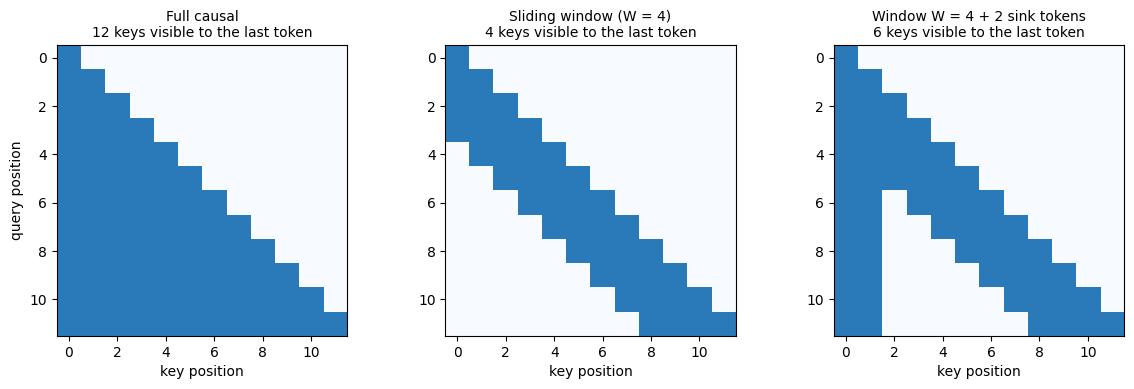

In [9]:
def window_mask(T, window, n_sink=0):
    # True = query i may attend to key j: causal AND (within the window OR a sink token)
    i, j = torch.arange(T)[:, None], torch.arange(T)[None, :]
    return (j <= i) & ((i - j < window) | (j < n_sink))

T_vis, W_vis = 12, 4
masks = [("Full causal", window_mask(T_vis, T_vis)),
         (f"Sliding window (W = {W_vis})", window_mask(T_vis, W_vis)),
         (f"Window W = {W_vis} + 2 sink tokens", window_mask(T_vis, W_vis, n_sink=2))]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (title, m) in zip(axes, masks):
    ax.imshow(m.float(), cmap="Blues", vmin=0, vmax=1.4)
    ax.set_title(f"{title}\n{int(m[-1].sum())} keys visible to the last token", fontsize=10)
    ax.set_xlabel("key position"); ax.set_xticks(range(0, T_vis, 2)); ax.set_yticks(range(0, T_vis, 2))
axes[0].set_ylabel("query position")
plt.tight_layout(); plt.show()

- **Full causal:** the last token reads all 12 keys, and the cache grows with every token.
- **Sliding window:** every row has at most `W = 4` entries, so the cache never holds more than 4 keys per layer.
- **Window + sinks:** the first two columns stay visible to every row, and the cache holds `2 + W` keys.

### 7.1 Information still travels far: the receptive field grows with depth

If a token sees only 4 positions, how can it use something said 100 tokens earlier? It can do so **indirectly, through the layers**. In layer 1, position 10 reads positions 7–10. But position 7's vector already contains information from positions 4–7, collected in the layer below. Each layer extends how far back the information reaches by `W − 1` positions, much like the receptive field of a stacked CNN.

The cell below computes this exactly: it multiplies the window masks layer by layer and plots which input positions can affect the **last** token after each layer.

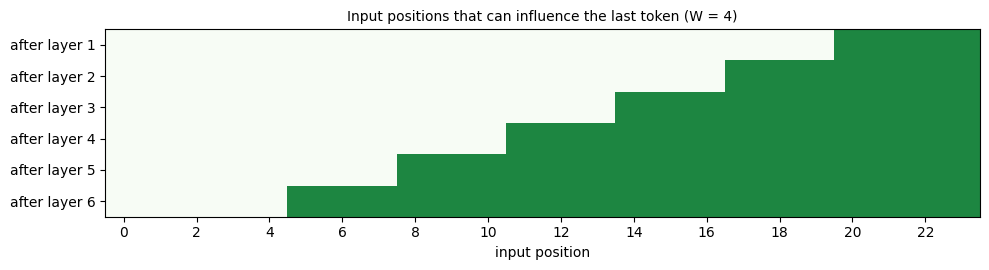

reach after L layers = L·(W − 1) + 1 positions: [4, 7, 10, 13, 16, 19]


In [10]:
T_rf, W_rf, n_layers_rf = 24, 4, 6
M = window_mask(T_rf, W_rf).float()
reach = torch.eye(T_rf)
rows = []
for layer in range(n_layers_rf):
    reach = (M @ reach).clamp(max=1)            # inputs that can influence each position after this layer
    rows.append(reach[-1])                      # ...for the last token
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.imshow(torch.stack(rows), cmap="Greens", vmin=0, vmax=1.3, aspect="auto")
ax.set_yticks(range(n_layers_rf)); ax.set_yticklabels([f"after layer {l + 1}" for l in range(n_layers_rf)])
ax.set_xlabel("input position"); ax.set_xticks(range(0, T_rf, 2))
ax.set_title(f"Input positions that can influence the last token (W = {W_rf})", fontsize=10)
plt.tight_layout(); plt.show()
for l, r in enumerate(rows):
    assert int(r.sum()) == min(T_rf, (l + 1) * (W_rf - 1) + 1)
print("reach after L layers = L·(W − 1) + 1 positions:", [int(r.sum()) for r in rows])

- Reach grows **linearly with depth**: `L · (W − 1) + 1` positions.
- **Mistral 7B** uses `W = 4096` with 32 layers, a theoretical reach of about 131K tokens with a cache of at most 4,096 entries per layer.
- The catch: information from far back reaches the current token only after being passed through several intermediate positions, and may be diluted on the way. It is not read directly. That is why many models **mix** layer types. **Local** layers use a sliding window. **Global** layers use ordinary full attention, still causal, so they can read any earlier token directly. Gemma 2 alternates the two one to one, with a window of 4,096 tokens. Gemma 3 uses five local layers for every global one, with a shorter window of 1,024 tokens. Only the global layers' caches grow with the context.

### 7.2 Implementation: a rolling-buffer cache

Compared with `GroupedQueryAttention`, the subclass below changes only two things:

1. **Prefill** applies the band mask from `window_mask`.
2. **Rolling buffer:** whenever a new token is appended, the cache is trimmed to the sink tokens plus the last `W` tokens, counting the new one. The trimmed cache then holds **exactly** the keys the new token may see, so decoding needs no mask.

In [11]:
class SlidingWindowAttention(GroupedQueryAttention):
    """GQA attention that only sees the last `window` tokens, plus `n_sink` always-visible first tokens."""

    def __init__(self, d_model, n_heads, n_kv_heads, window, n_sink=0):
        super().__init__(d_model, n_heads, n_kv_heads)
        self.window, self.n_sink = window, n_sink

    def trim(self, t):                                             # keep sink tokens + the last `window` tokens
        if t.size(2) <= self.n_sink + self.window:
            return t
        return torch.cat([t[:, :, :self.n_sink], t[:, :, -self.window:]], dim=2)

    def forward(self, x, cache=None):
        B, T_new, _ = x.shape
        assert cache is None or T_new == 1, "prefill without a cache, then decode one token at a time"
        Q = self.split_heads(self.W_q(x), self.n_heads)
        K = self.split_heads(self.W_k(x), self.n_kv_heads)
        V = self.split_heads(self.W_v(x), self.n_kv_heads)
        if cache is not None:
            K, V = torch.cat([cache[0], K], dim=2), torch.cat([cache[1], V], dim=2)
            K, V = self.trim(K), self.trim(V)                      # change 2: rolling buffer (evict the oldest)

        scores = Q @ K.repeat_interleave(self.group_size, dim=1).transpose(-2, -1) / math.sqrt(self.head_dim)
        if cache is None:                                          # change 1: band mask during prefill
            scores = scores.masked_fill(~window_mask(T_new, self.window, self.n_sink), float("-inf"))
        weights = scores.softmax(dim=-1)
        out = (weights @ V.repeat_interleave(self.group_size, dim=1)).transpose(1, 2).reshape(B, T_new, -1)

        return self.W_o(out), weights, (self.trim(K), self.trim(V))


torch.manual_seed(3)
prompt, new_tokens = torch.randn(1, 6, d_model), torch.randn(1, 10, d_model)
for n_sink in (0, 2):
    layer = SlidingWindowAttention(d_model, n_heads, n_kv_heads=2, window=4, n_sink=n_sink)
    with torch.no_grad():
        _, _, cache = layer(prompt)
        lengths, step_outputs = [cache[0].size(2)], []
        for t in range(new_tokens.size(1)):
            out, _, cache = layer(new_tokens[:, t:t + 1], cache=cache)
            step_outputs.append(out); lengths.append(cache[0].size(2))
        full, _, _ = layer(torch.cat([prompt, new_tokens], dim=1))   # whole sequence with the band mask
    same = torch.allclose(torch.cat(step_outputs, dim=1), full[:, -10:], atol=1e-5)
    print(f"window=4, sinks={n_sink}: cached tokens per step {lengths} | matches full masked pass: {same}")
    assert same and max(lengths) == n_sink + 4

window=4, sinks=0: cached tokens per step [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] | matches full masked pass: True
window=4, sinks=2: cached tokens per step [6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6] | matches full masked pass: True


- The cache length is capped at `n_sink + W` (4 or 6) no matter how many tokens are generated.
- Decoding with the rolling buffer gives exactly the same result as running the whole sequence with the band mask, so the trimming is correct.
- **Positions:** this toy layer has no positional encoding. Real models with RoPE (see [positional encodings](positional_encodings.ipynb)) need care about which position each cached token is treated as having. StreamingLLM assigns positions **within the cache** rather than in the original text.

### What sliding windows do at real scale

Below is the KV cache for one sequence as the context grows, using Mistral-7B-like sizes (32 layers, 8 K/V heads, `W = 4096`):

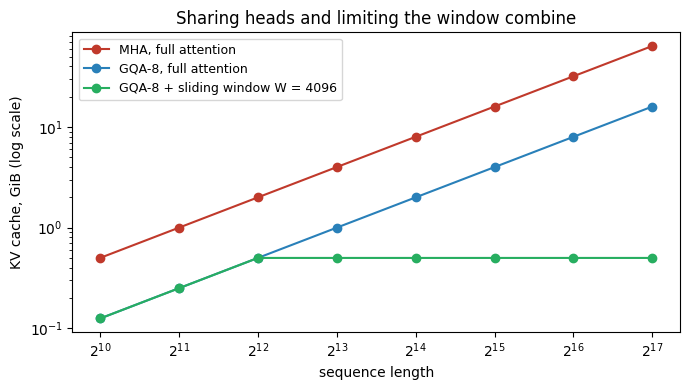

at 128K tokens: MHA 64 GiB, GQA-8 16 GiB, GQA-8 + window 0.50 GiB


In [12]:
seq_lens = [2**k for k in range(10, 18)]                                       # 1K ... 128K tokens
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(seq_lens, [kv_cache_bytes(1, t, 32) / 2**30 for t in seq_lens], "o-", color=colors[0], label="MHA, full attention")
ax.plot(seq_lens, [kv_cache_bytes(1, t, 8) / 2**30 for t in seq_lens], "o-", color=colors[1], label="GQA-8, full attention")
ax.plot(seq_lens, [kv_cache_bytes(1, min(t, 4096), 8) / 2**30 for t in seq_lens], "o-", color=colors[3],
        label="GQA-8 + sliding window W = 4096")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("sequence length"); ax.set_ylabel("KV cache, GiB (log scale)")
ax.set_title("Sharing heads and limiting the window combine"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print(f"at 128K tokens: MHA {kv_cache_bytes(1, 2**17, 32) / 2**30:.0f} GiB, GQA-8 {kv_cache_bytes(1, 2**17, 8) / 2**30:.0f} GiB, "
      f"GQA-8 + window {kv_cache_bytes(1, 4096, 8) / 2**30:.2f} GiB")

- The two savings **multiply**: GQA divides the cache by `H/G`, and the window caps its length.
- The cost: anything outside the window is reachable only **indirectly**, through the layers (Section 7.1). Tasks that need exact recall from far back, such as quoting a fact from the start of a long document, can suffer. That is why recent models mix windowed and global layers.

### 7.3 Attention sinks: why plain windows break, and the fix

In many trained LLMs, a large share of attention goes to the **very first token(s)**, even when they carry no meaning (e.g. `<s>` or “The”). Xiao et al. (2023) called these **attention sinks**. A plausible explanation:

- Softmax forces each head's weights to **sum to 1**, even when the head has nothing useful to read.
- The first token is visible to **every** later position, so models learn to use it as a parking spot for unneeded attention. Its value vector contributes little.

**What breaks:** once a plain sliding window drops the first token, that parked attention has nowhere to go. Softmax redistributes it over the remaining tokens, and the hidden states move away from anything the model saw during training. StreamingLLM reports that perplexity **explodes** as soon as the initial tokens leave the window.

**The fix:** always keep the first few tokens, which is the `n_sink` option above. StreamingLLM found that **4 sink tokens** plus a recent window were enough for stable generation over millions of tokens, without any retraining.

The toy example below uses **made-up** scores that mimic the pattern: one key (the sink) has a high score, and its value vector is close to zero.

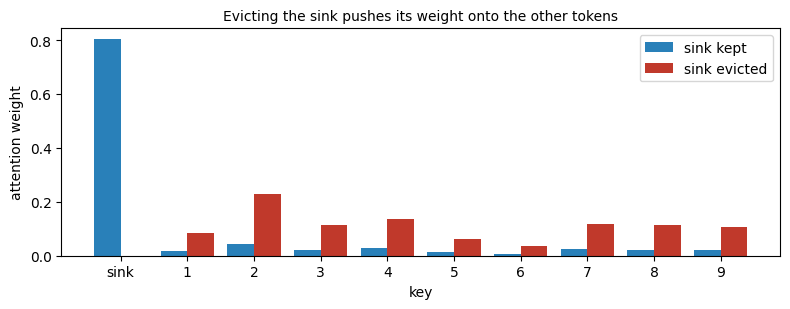

weight on the sink: 0.80
output norm with sink: 0.26 | after eviction: 1.00  (3.8× larger)


In [13]:
torch.manual_seed(4)
n_keys = 10
scores = 0.5 * torch.randn(n_keys); scores[0] = 4.0           # key 0 = sink: high score
values = torch.randn(n_keys, 8); values[0] = 0.05 * values[0]   # sink's value: nearly nothing

w_with = scores.softmax(dim=0)
w_without = scores[1:].softmax(dim=0)                           # sink evicted: renormalize over the rest
out_with, out_without = w_with @ values, w_without @ values[1:]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(torch.arange(n_keys) - 0.2, w_with, width=0.4, label="sink kept", color="#2980b9")
ax.bar(torch.arange(1, n_keys) + 0.2, w_without, width=0.4, label="sink evicted", color="#c0392b")
ax.set_xticks(range(n_keys)); ax.set_xticklabels(["sink"] + [str(k) for k in range(1, n_keys)])
ax.set_xlabel("key"); ax.set_ylabel("attention weight"); ax.legend()
ax.set_title("Evicting the sink pushes its weight onto the other tokens", fontsize=10)
plt.tight_layout(); plt.show()
print(f"weight on the sink: {w_with[0]:.2f}")
print(f"output norm with sink: {out_with.norm():.2f} | after eviction: {out_without.norm():.2f}  "
      f"({out_without.norm() / out_with.norm():.1f}× larger)")

- With the sink, most of the weight is parked on a token that contributes almost nothing, so the output stays small.
- After eviction, the same weight is spread over real tokens, and the output becomes several times larger. Every later layer then receives inputs unlike anything it saw during training.

**Sinks in a real model.** The cell below plots the attention of **DistilGPT-2** (a 6-layer distilled GPT-2), averaged over heads. Look for a bright **first column**.

> **Download:** on the first run this fetches `distilgpt2` from Hugging Face (~350 MB, cached afterwards; needs `transformers`). Set `RUN_SINK_DEMO = False` to skip it.

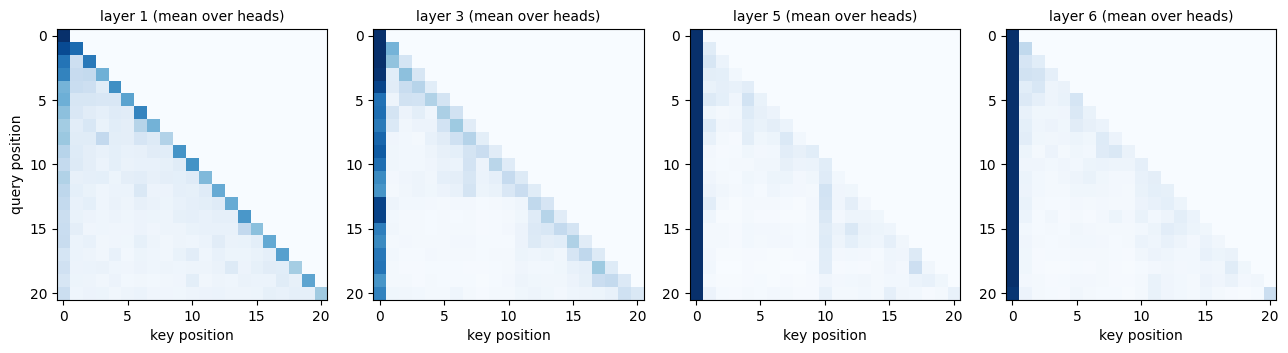

layer  1: average weight on the first token = 0.17
layer  2: average weight on the first token = 0.35
layer  3: average weight on the first token = 0.44
layer  4: average weight on the first token = 0.76
layer  5: average weight on the first token = 0.70
layer  6: average weight on the first token = 0.69


In [14]:
RUN_SINK_DEMO = True  # downloads distilgpt2 (~350 MB) on first run; set False to skip

if RUN_SINK_DEMO:
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok = AutoTokenizer.from_pretrained("distilbert/distilgpt2")
    lm = AutoModelForCausalLM.from_pretrained("distilbert/distilgpt2", attn_implementation="eager").eval()
    text = "The robot opened the door and walked into the quiet library, where an old man was reading a book."
    enc = tok(text, return_tensors="pt")
    with torch.inference_mode():
        attentions = lm(**enc, output_attentions=True).attentions      # per layer: (1, H, T, T)
    show = [0, 2, 4, 5]
    fig, axes = plt.subplots(1, len(show), figsize=(13, 3.3))
    for ax, l in zip(axes, show):
        ax.imshow(attentions[l][0].mean(dim=0), cmap="Blues", vmin=0, vmax=0.6)
        ax.set_title(f"layer {l + 1} (mean over heads)", fontsize=10); ax.set_xlabel("key position")
        ax.set_xticks(range(0, enc["input_ids"].size(1), 5)); ax.set_yticks(range(0, enc["input_ids"].size(1), 5))
    axes[0].set_ylabel("query position")
    plt.tight_layout(); plt.show()
    for l, a in enumerate(attentions):
        print(f"layer {l + 1:>2}: average weight on the first token = {a[0, :, 5:, 0].mean():.2f}")
else:
    print("Sink demo skipped. Set RUN_SINK_DEMO = True to download distilgpt2 and inspect its attention.")

- **Layer 1** mostly attends to the token itself and its immediate neighbours: ordinary local patterns.
- **From the middle layers on**, the first column dominates. In our run, about 70% of all attention in layers 4–6 goes to the first token, which here is just “The”.
- This is exactly the attention a plain sliding window would throw away once “The” leaves the window, and exactly what keeping a few sink tokens preserves.

## 8. Summary

| Method | What changes | Main benefit | Cost |
| --- | --- | --- | --- |
| Multi-head attention | baseline: separate Q, K, V per head | most expressive | largest KV cache |
| Grouped-query attention | K/V heads shared within groups | cache ÷ `H/G`, quality close to MHA | slightly less expressive |
| Multi-query attention | one K/V head for all query heads | smallest cache, fastest decoding | quality can drop |
| Sliding-window attention | each token sees only the last `W` tokens | cache capped at `W` per layer | far context only reachable indirectly, through the layers |
| Attention sinks | always keep the first few tokens in the window | stable long generation with a window | a few extra cached tokens |
| KV cache | stores past K, V during generation | no recomputation of past tokens | memory grows with batch × length |

**Common misconceptions**

- *“MQA removes heads.”* No: it keeps `H` query heads and `H` attention patterns (Section 4).
- *“MQA changes the attention formula.”* No: only the shapes and the sharing of K and V change.
- *“MQA mainly speeds up training.”* No: the main benefit is in decoding, where reading the cache is the bottleneck (Section 2).
- *“A smaller KV cache means smaller attention scores.”* No: scores stay `(B, H, Tq, Tk)`. The saving is in what is **stored and read**.

## 9. Check your understanding

1. With `H = 16`, how many K/V heads are cached by MHA, by GQA with 4 groups, and by MQA?
2. Why can MQA heads produce different attention patterns when they share keys?
3. During decoding, why does reading fewer bytes help more than computing fewer FLOPs?
4. In `GroupedQueryAttention`, why is the cache stored **before** `repeat_interleave`?
5. Why might GQA be preferred over MQA?
6. With `W = 4096` and 32 layers, how far back can information reach the last token? Why is that reach weaker than full attention?
7. Why does a plain sliding window break once the first tokens are evicted, and how do attention sinks fix it?

<details>
<summary><b>Show answers</b></summary>

1. MHA: 16 K and 16 V heads. GQA-4: 4 of each. MQA: 1 of each.
2. Each head has its own query projection, so its dot products with the shared keys, and therefore its softmax weights, differ.
3. With `Tq = 1`, each cached byte is used for only about `H/G` FLOPs. The GPU waits on memory, so reading less data is what speeds it up.
4. The repeated copies contain no new information. Storing only the `G` original heads is exactly the memory saving; repetition (or broadcasting) happens on the fly.
5. GQA keeps most of the cache saving while giving each group its own keys and values, so quality stays closer to MHA.
6. About `32 × 4095 + 1 ≈ 131K` tokens. Distant information arrives only indirectly, passed through intermediate positions over several layers, so it can be diluted. It is never read directly.
7. Models learn to park unneeded attention on the first token(s). After eviction, softmax spreads that weight over real tokens, pushing hidden states away from what the model saw in training. Keeping a few sink tokens in the cache restores a place to park it.

</details>

## References

1. Vaswani et al., [Attention Is All You Need](https://arxiv.org/abs/1706.03762), 2017.
2. Shazeer, [Fast Transformer Decoding: One Write-Head is All You Need](https://arxiv.org/abs/1911.02150), 2019. (MQA)
3. Ainslie et al., [GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints](https://arxiv.org/abs/2305.13245), 2023.
4. Beltagy et al., [Longformer: The Long-Document Transformer](https://arxiv.org/abs/2004.05150), 2020. (sliding-window attention)
5. Xiao et al., [Efficient Streaming Language Models with Attention Sinks](https://arxiv.org/abs/2309.17453), 2023. (StreamingLLM)
6. Touvron et al., [Llama 2: Open Foundation and Fine-Tuned Chat Models](https://arxiv.org/abs/2307.09288), 2023 · Jiang et al., [Mistral 7B](https://arxiv.org/abs/2310.06825), 2023 · Gemma Team, [Gemma 2](https://arxiv.org/abs/2408.00118), 2024 · Gemma Team, [Gemma 3 Technical Report](https://arxiv.org/abs/2503.19786), 2025 · Almazrouei et al., [The Falcon Series of Open Language Models](https://arxiv.org/abs/2311.16867), 2023.
7. Course notebooks: [Attention Is All You Need](Attention_Is_All_You_Need.ipynb) · [GPT-2](GPT-2.ipynb) · [key–value cache](key_value_cache.ipynb) · [FlashAttention](flash_attention.ipynb).